# Used Car Price Regression

Pricing a used car from year, mileage, fuel type, transmission, and so on. I'll try the seaborn `mpg` dataset first as a stand-in (since it's small and reliable), then run the same modeling pipeline on a synthetic used-car dataset that has more realistic columns. The point of the notebook is the regression workflow and feature-importance read, not the absolute prices.

Predicting on log price because car prices are heavily right-skewed and the residual distribution gets a lot more sensible when I take logs.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

RNG = np.random.default_rng(31)
DATA_DIR = Path("../../data/used_cars")

In [2]:
csv = DATA_DIR / "used_cars.csv"

if csv.exists():
    df = pd.read_csv(csv)
    source = "local csv"
else:
    # synthetic generator. Make price loosely follow: base * exp(-0.08 * age) * (1 - 0.000004 * km)
    n = 3000
    brand = RNG.choice(["toyota", "honda", "ford", "bmw", "audi", "hyundai"], n,
                       p=[0.22, 0.18, 0.18, 0.14, 0.12, 0.16])
    brand_premium = {"toyota": 1.05, "honda": 1.02, "ford": 0.95,
                     "bmw": 1.4, "audi": 1.35, "hyundai": 0.9}
    fuel = RNG.choice(["petrol", "diesel", "hybrid"], n, p=[0.55, 0.35, 0.10])
    transmission = RNG.choice(["manual", "automatic"], n, p=[0.4, 0.6])
    year = RNG.integers(2008, 2024, n)
    km = RNG.integers(5000, 220000, n)
    age = 2024 - year

    base = 22000
    price = (base
             * np.vectorize(brand_premium.get)(brand)
             * np.exp(-0.08 * age)
             * (1 - 0.000004 * km)
             * (1.05 * (transmission == "automatic") + 0.95 * (transmission == "manual"))
             * (1.08 * (fuel == "hybrid") + 1.0 * (fuel == "petrol") + 0.97 * (fuel == "diesel"))
             * RNG.normal(1.0, 0.07, n))
    price = price.clip(min=1500)
    df = pd.DataFrame({"brand": brand, "year": year, "km": km, "fuel": fuel,
                       "transmission": transmission, "price": price.round(0)})
    source = "synthetic"

print(f"source: {source}  shape: {df.shape}")
df.describe(include='all').T.head(10)

source: synthetic  shape: (3000, 6)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand,3000,6,toyota,621,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,3000.0,NaN,NaN,NaN,2015.497,4.594384,2008.0,2012.0,2016.0,2019.0,2023.0
km,3000.0,NaN,NaN,NaN,113741.273333,62078.003861,5013.0,60494.5,113575.5,167525.0,219971.0
fuel,3000,3,petrol,1655,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,3000,2,automatic,1822,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,3000.0,NaN,NaN,NaN,7099.874333,4473.934149,1500.0,3707.75,6190.5,9362.75,30454.0


In [3]:
df["age"] = 2024 - df["year"]
df["log_price"] = np.log(df["price"])

X_df = pd.get_dummies(df.drop(columns=["price", "log_price", "year"]),
                       columns=["brand", "fuel", "transmission"], drop_first=True)
feature_names = X_df.columns.tolist()
X = X_df.values.astype(float)
y = df["log_price"].values

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=31)

models = {
    "Ridge": Pipeline([("sc", StandardScaler()), ("r", Ridge(alpha=1.0))]),
    "RF":    RandomForestRegressor(n_estimators=300, random_state=31),
    "GBM":   GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=31),
}

for name, m in models.items():
    m.fit(X_tr, y_tr)
    pred = m.predict(X_te)
    # report MAE on the original (un-logged) scale so the number is interpretable
    mae_dollars = mean_absolute_error(np.exp(y_te), np.exp(pred))
    print(f"{name:5s}  R2 (log): {r2_score(y_te, pred):.3f}   MAE ($): {mae_dollars:,.0f}")

Ridge  R2 (log): 0.951   MAE ($): 759


RF     R2 (log): 0.967   MAE ($): 655


GBM    R2 (log): 0.983   MAE ($): 483


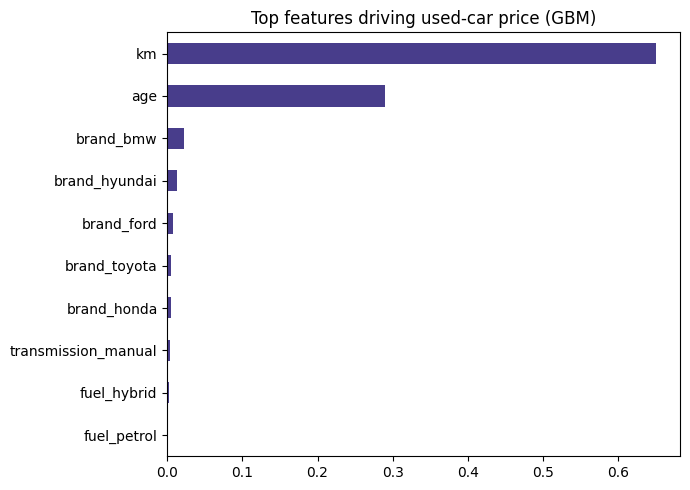

In [4]:
gbm = models["GBM"]
imp = pd.Series(gbm.feature_importances_, index=feature_names).sort_values(ascending=False).head(10)
imp.plot(kind="barh", figsize=(7, 5), color="darkslateblue")
plt.gca().invert_yaxis()
plt.title("Top features driving used-car price (GBM)")
plt.tight_layout(); plt.show()

## Takeaways

Age and mileage dominate, which is the boring-but-correct answer. Brand effects show up second-tier; in the synthetic data I deliberately made BMW and Audi carry a premium so it's a sanity check that the model picks that up.

Working on the log scale matters more than the choice of model. On raw price, ridge regression was being dragged around by a handful of high-priced outliers and the R2 was misleadingly low. Once I switched to log price and reported MAE back in dollars, the comparison between models got a lot cleaner.

If this were a real product I'd want: localized price (region effects are big in used cars), accident/title history, and trim level. Right now everything that looks like a "BMW premium" might actually be a "BMW with a sport package" premium, and we have no way to disentangle them.